Loading data...
Preprocessing and merging data...
Scaling and splitting data...
Building and training the LSTM model...
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


384/384 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0375 - val_loss: 0.0017
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0034 - val_loss: 0.0015
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0027 - val_loss: 0.0015
Epoch 4/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0023 - val_loss: 0.0014
Epoch 5/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0016
Epoch 6/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0019 - val_loss: 0.0014
Epoch 7/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0018 - val_loss: 0.0014
Epoch 8/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 9/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 10/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 11/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 12/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.

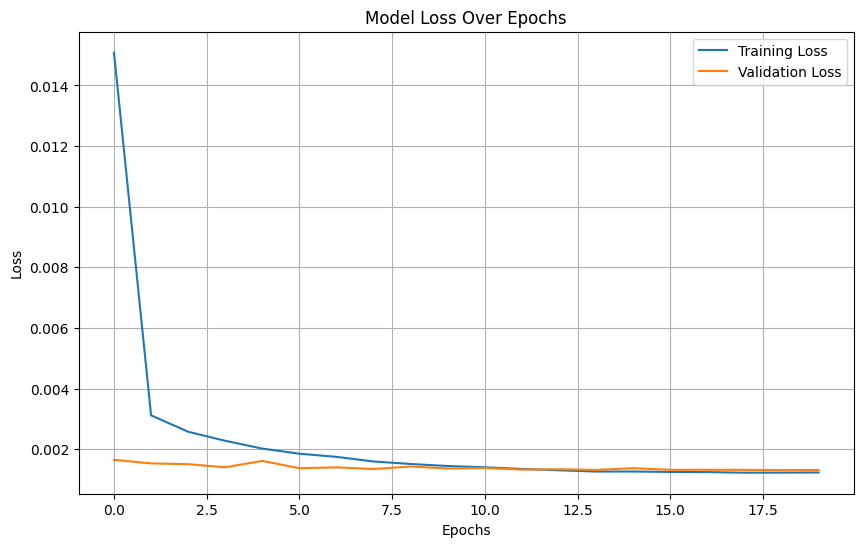

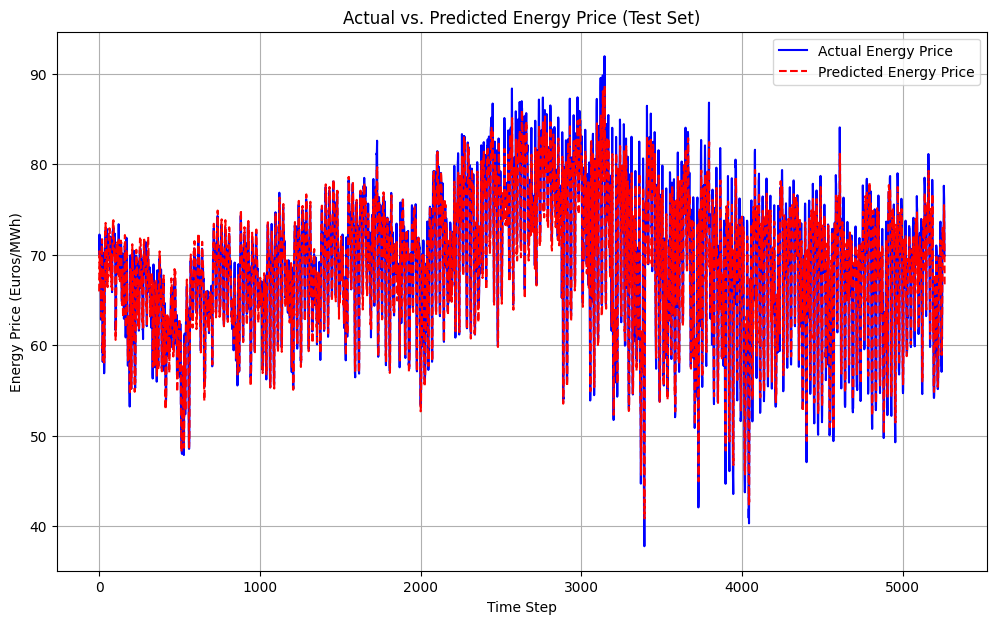

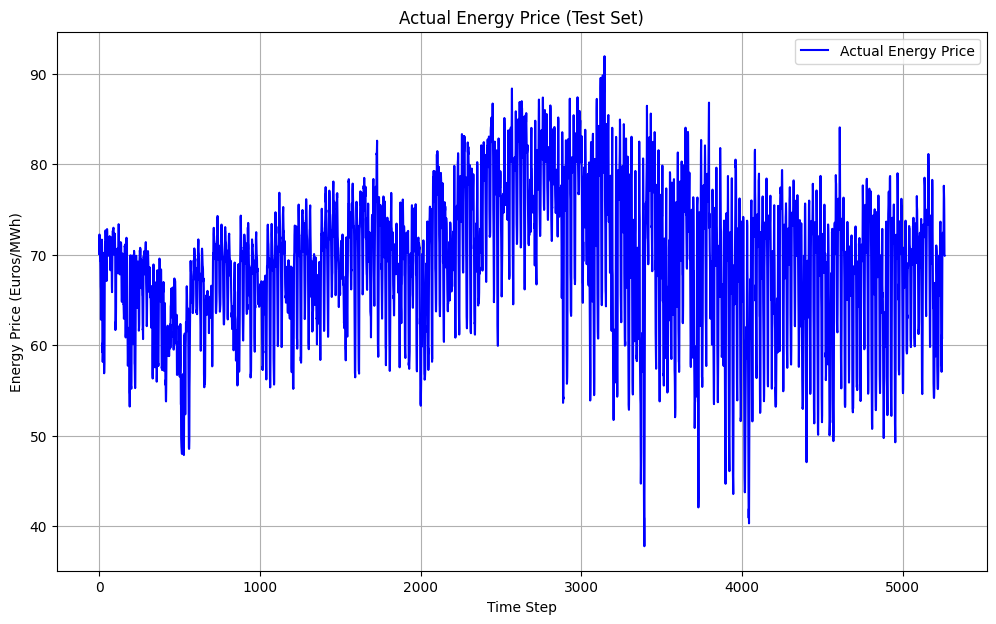

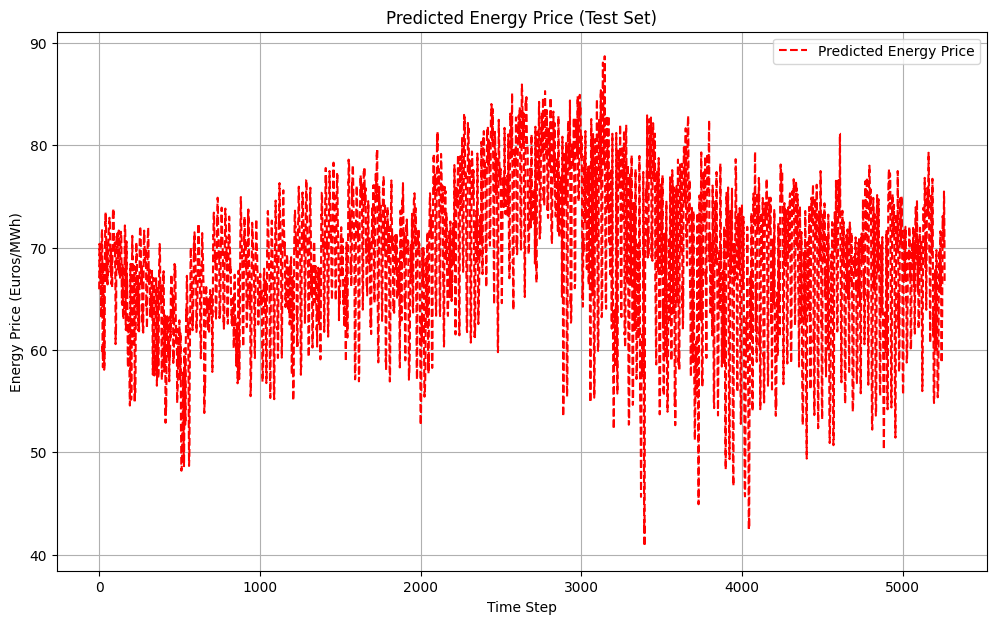

In [5]:
# This script performs energy price forecasting using a Deep Learning model.
# It integrates energy and weather data, processes it, trains an LSTM model, and evaluates its performance.

# 1. Import necessary libraries
import pandas as pd # For data manipulation and analysis.
import numpy as np # For numerical operations, especially with arrays.
import matplotlib.pyplot as plt # For creating static, interactive, and animated visualizations.
from sklearn.preprocessing import MinMaxScaler # To scale features to a given range.
from sklearn.metrics import mean_absolute_error, mean_squared_error # To evaluate model performance.
import tensorflow as tf # The core library for Deep Learning.
from tensorflow.keras.models import Sequential # To build a simple, layer-by-layer model.
from tensorflow.keras.layers import LSTM, Dense, Dropout # Key layers for the model.

# 2. Load the datasets
# Assuming 'energy_dataset.csv' and 'weather_features.csv' are in the same directory.
print("Loading data...")
try:
    energy_df = pd.read_csv('energy_dataset.csv')
    weather_df = pd.read_csv('weather_features.csv')
except FileNotFoundError:
    print("Error: One or both data files were not found. Please ensure 'energy_dataset.csv' and 'weather_features.csv' are in the same directory.")
    exit()

# 3. Data Preprocessing
print("Preprocessing and merging data...")

# Convert timestamps to a consistent datetime format and set as index.
energy_df['time'] = pd.to_datetime(energy_df['time'], utc=True)
energy_df.set_index('time', inplace=True)
weather_df['dt_iso'] = pd.to_datetime(weather_df['dt_iso'], utc=True)
weather_df.set_index('dt_iso', inplace=True)

# Select a single city to simplify the weather data for this example.
# We will use "Madrid" as it is a major city in Spain.
weather_madrid = weather_df[weather_df['city_name'] == 'Madrid'].copy()

# Drop unnecessary columns from the weather data.
weather_madrid.drop(columns=['city_name', 'weather_id', 'weather_main', 'weather_description', 'weather_icon', 'rain_1h', 'rain_3h', 'snow_3h'], inplace=True)

# Resample to match the hourly frequency of the energy data.
# This ensures both dataframes have the same index for merging.
weather_madrid = weather_madrid.resample('h').mean()

# Merge the two dataframes on their time-based index.
# This combines energy data with corresponding weather features.
df = pd.merge(energy_df, weather_madrid, left_index=True, right_index=True, how='inner')


# Select features and the target variable for the model.
# The target is 'price actual', which we will forecast.
# Features include relevant energy data, weather data, and time-based features.
features = ['total load actual', 'generation wind onshore', 'temp', 'pressure', 'humidity']
target = 'price actual'

# Feature Engineering: Create time-based features from the index.
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month

# Feature Engineering: Create a lagged feature of the target variable.
# The model will use the previous hour's price to predict the current one.
df['price_lag_1'] = df[target].shift(1)

# Handle any remaining missing values by filling them with the mean of the column.
# This is done after creating all features to avoid dropping data.
df.fillna(df.mean(), inplace=True)


# Update the features list to include the newly created ones.
final_features = ['total load actual', 'generation wind onshore', 'temp', 'pressure', 'humidity', 'hour', 'day_of_week', 'month', 'price_lag_1']

# 4. Data Scaling and Splitting
print("Scaling and splitting data...")

# Create two separate scalers: one for features and one for the target.
feature_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler = MinMaxScaler(feature_range=(0, 1))

# Scale the final features and the target.
scaled_features = feature_scaler.fit_transform(df[final_features])
scaled_target = target_scaler.fit_transform(df[[target]])

# Combine the scaled features and target into a single array for splitting.
scaled_data = np.hstack((scaled_features, scaled_target))

# Split the data into training, validation, and test sets chronologically.
# A typical split is 70% for training, 15% for validation, and 15% for testing.
train_size = int(len(scaled_data) * 0.70)
val_size = int(len(scaled_data) * 0.15)
train_data = scaled_data[0:train_size, :]
val_data = scaled_data[train_size:train_size + val_size, :]
test_data = scaled_data[train_size + val_size:len(scaled_data), :]

# Define a function to create sequences for the LSTM model.
# The LSTM model requires data to be in a 3D format: [samples, timesteps, features].
def create_sequences(data, n_features):
    X, y = [], []
    for i in range(len(data)):
        # The first n_features columns are the input features (X).
        # The last column is the target variable (y).
        X.append(data[i, :-1])
        y.append(data[i, -1])
    return np.array(X), np.array(y)

# Create sequences for each dataset.
X_train, y_train = create_sequences(train_data, len(final_features))
X_val, y_val = create_sequences(val_data, len(final_features))
X_test, y_test = create_sequences(test_data, len(final_features))

# Reshape the input data to the required 3D format for LSTM layers.
# The shape is (number of samples, timesteps, number of features).
# Here, timesteps = 1.
X_train = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1]))
X_val = np.reshape(X_val, (X_val.shape[0], 1, X_val.shape[1]))
X_test = np.reshape(X_test, (X_test.shape[0], 1, X_test.shape[1]))

# 5. Build and Train the LSTM Model
print("Building and training the LSTM model...")

# Define the LSTM model architecture.
model = Sequential()
# Add the first LSTM layer with 50 units. 'return_sequences=True' is used when stacking LSTM layers.
model.add(LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2)) # A dropout layer to prevent overfitting.
# Add a second LSTM layer.
model.add(LSTM(50))
model.add(Dropout(0.2))
# Add the final Dense layer with 1 unit, as we are predicting a single value (energy price).
model.add(Dense(1))

# Compile the model. 'adam' is a popular optimizer and 'mse' is the loss function for regression tasks.
model.compile(optimizer='adam', loss='mse')

# Train the model. 'epochs' is the number of times the model will go through the entire training dataset.
history = model.fit(X_train, y_train, epochs=20, batch_size=64, validation_data=(X_val, y_val), verbose=1)

# 6. Model Evaluation
print("Evaluating the model on the test set...")

# Make predictions on the test data.
y_pred = model.predict(X_test)

# Inverse transform the predictions and actual values to their original scale.
# This allows us to interpret the results in the correct units (Euros/MWh).
y_pred_unscaled = target_scaler.inverse_transform(y_pred)
y_test_unscaled = target_scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate and print the evaluation metrics.
mae = mean_absolute_error(y_test_unscaled, y_pred_unscaled)
mse = mean_squared_error(y_test_unscaled, y_pred_unscaled)
rmse = np.sqrt(mse)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# 7. Visualization
print("Generating visualizations...")

# Plot the training and validation loss over epochs.
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot a section of the actual vs. predicted energy prices for visual comparison.
plt.figure(figsize=(12, 7))
# Plot the actual energy price.
plt.plot(y_test_unscaled, label='Actual Energy Price', color='blue')
# Plot the predicted energy price.
plt.plot(y_pred_unscaled, label='Predicted Energy Price', color='red', linestyle='--')
plt.title('Actual vs. Predicted Energy Price (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Energy Price (Euros/MWh)')
plt.legend()
plt.grid(True)
plt.show()

# Plot actual energy price separately
plt.figure(figsize=(12, 7))
plt.plot(y_test_unscaled, label='Actual Energy Price', color='blue')
plt.title('Actual Energy Price (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Energy Price (Euros/MWh)')
plt.legend()
plt.grid(True)
plt.show()

# Plot predicted energy price separately
plt.figure(figsize=(12, 7))
plt.plot(y_pred_unscaled, label='Predicted Energy Price', color='red', linestyle='--')
plt.title('Predicted Energy Price (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Energy Price (Euros/MWh)')
plt.legend()
plt.grid(True)
plt.show()

Loading data...
Preprocessing and merging data...
Scaling and splitting data...

Building and training the LSTM model...
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


384/384 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.0449 - val_loss: 0.0022
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0033 - val_loss: 0.0016
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0028 - val_loss: 0.0016
Epoch 4/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0024 - val_loss: 0.0014
Epoch 5/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0014
Epoch 6/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0019 - val_loss: 0.0014
Epoch 7/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0018 - val_loss: 0.0014
Epoch 8/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0017 - val_loss: 0.0016
Epoch 9/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 10/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 11/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 12/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0301 - val_loss: 0.0015
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 9.6112e-04 - val_loss: 0.0012
Epoch 4/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 9.2232e-04 - val_loss: 0.0013
Epoch 5/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 9.2164e-04 - val_loss: 0.0013
Epoch 6/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.8902e-04 - val_loss: 0.0013
Epoch 7/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.7586e-04 - val_loss: 0.0011
Epoch 8/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.7042e-04 - val_loss: 0.0010
Epoch 9/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 8.5739e-04 - val_loss: 9.8292e-04
Epoch 10/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 8.1682e-04 - val_loss: 9.6001e-04
Epoch 11/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 7.5464e-04 - val_loss: 9.3371e-04
Epoch 12/20
384

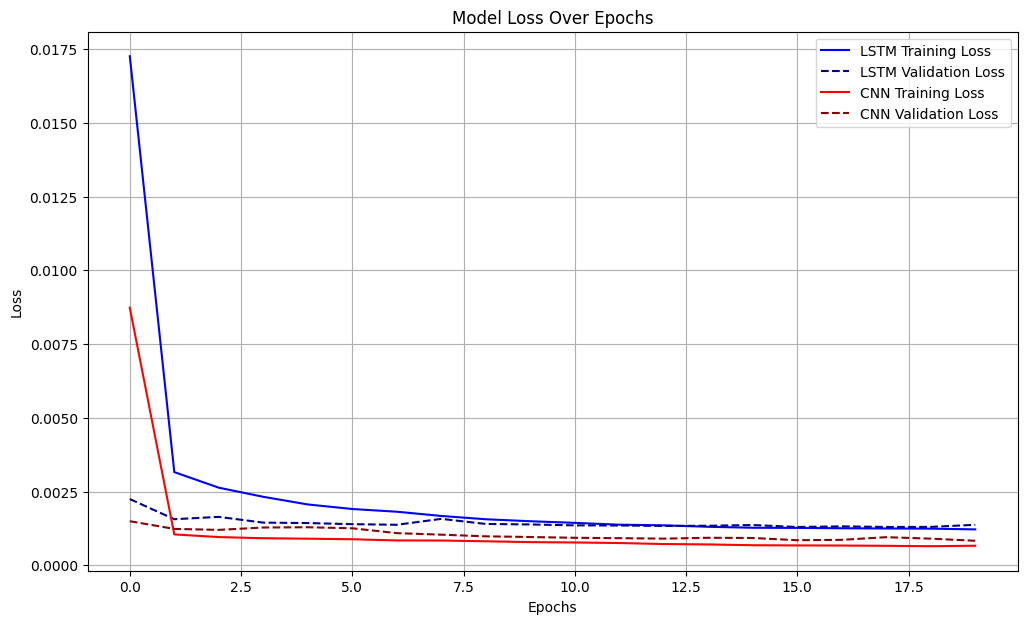

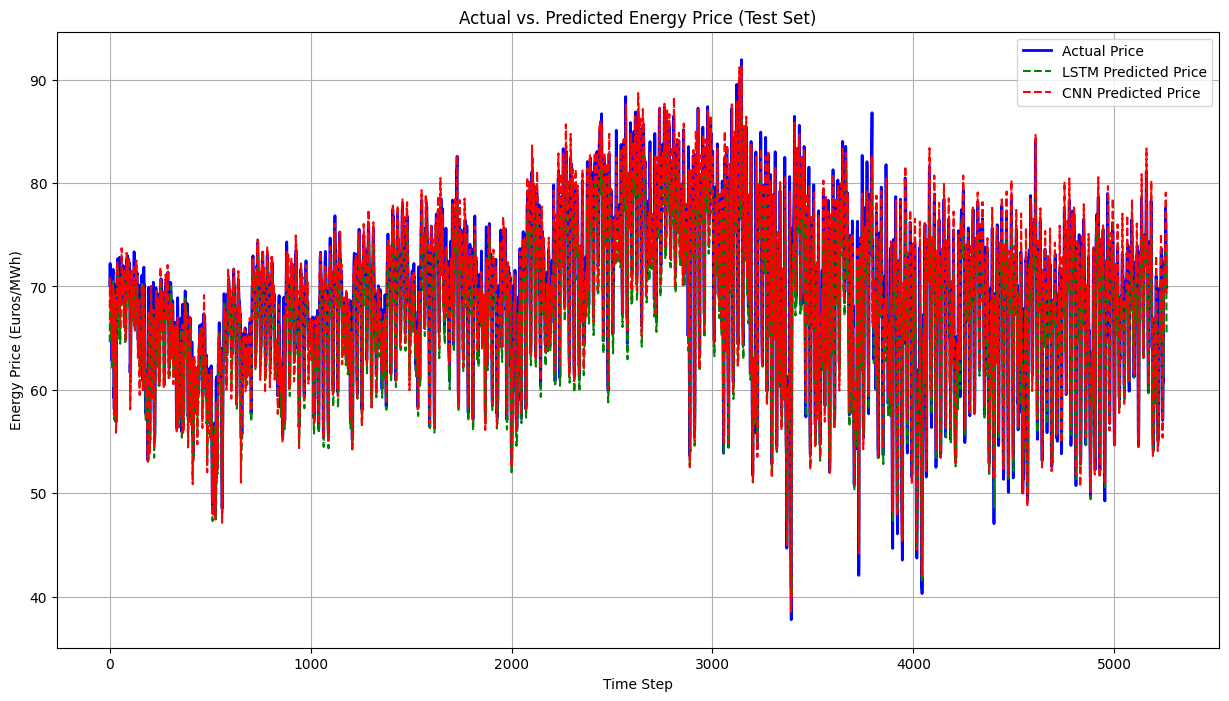

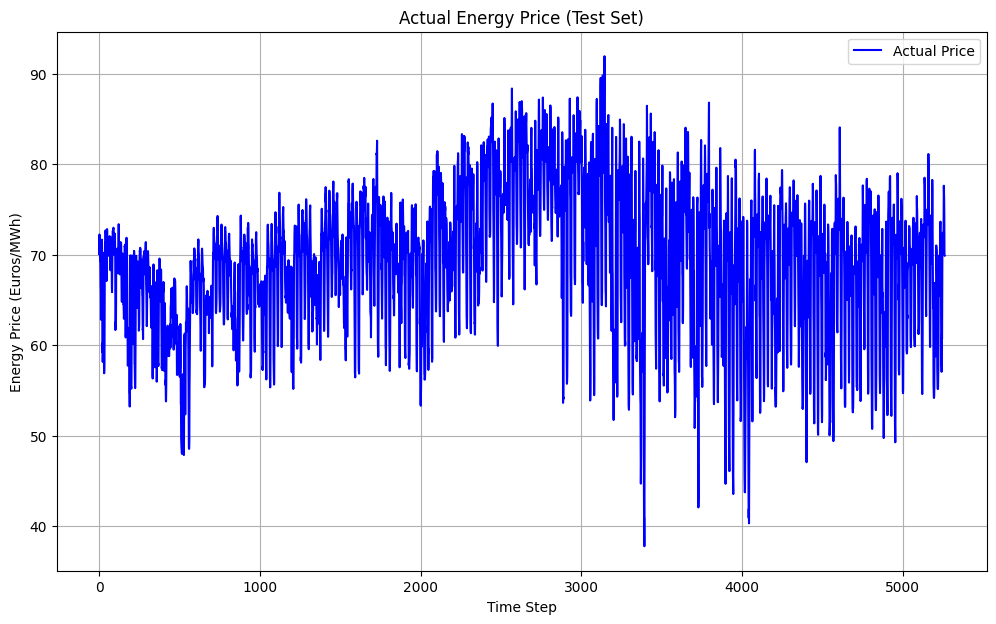

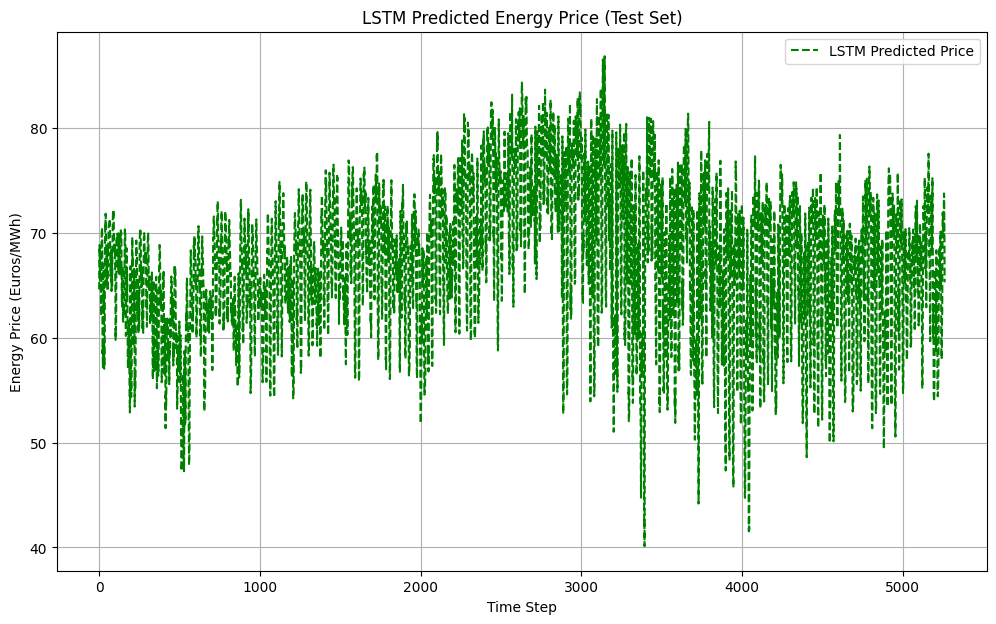

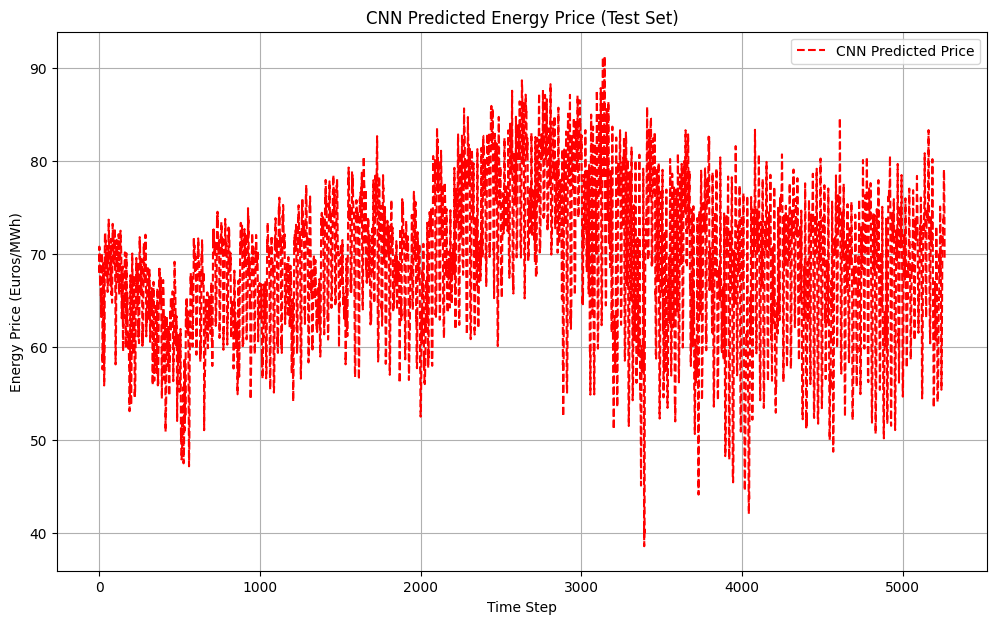

In [8]:
# This script performs energy price forecasting using two different Deep Learning models:
# a Long Short-Term Memory (LSTM) network and a Convolutional Neural Network (CNN).
# It processes historical energy and weather data, trains both models, and compares their performance.

# 1. Import necessary libraries
import pandas as pd # For data manipulation and analysis.
import numpy as np # For numerical operations, especially with arrays.
import matplotlib.pyplot as plt # For creating static, interactive, and animated visualizations.
from sklearn.preprocessing import MinMaxScaler # To scale features to a given range.
from sklearn.metrics import mean_absolute_error, mean_squared_error # To evaluate model performance.
import tensorflow as tf # The core library for Deep Learning.
from tensorflow.keras.models import Sequential # To build a simple, layer-by-layer model.
from tensorflow.keras.layers import LSTM, Dense, Dropout, Conv1D, Flatten # Key layers for the models.

# 2. Load the datasets
# Assuming 'energy_dataset.csv' and 'weather_features.csv' are in the same directory.
print("Loading data...")
try:
    energy_df = pd.read_csv('energy_dataset.csv')
    weather_df = pd.read_csv('weather_features.csv')
except FileNotFoundError:
    print("Error: One or both data files were not found. Please ensure 'energy_dataset.csv' and 'weather_features.csv' are in the same directory.")
    exit()

# 3. Data Preprocessing
print("Preprocessing and merging data...")

# Convert timestamps to a consistent datetime format and set as index.
energy_df['time'] = pd.to_datetime(energy_df['time'], utc=True)
energy_df.set_index('time', inplace=True)
weather_df['dt_iso'] = pd.to_datetime(weather_df['dt_iso'], utc=True)
weather_df.set_index('dt_iso', inplace=True)

# Select a single city to simplify the weather data for this example.
# We will use "Madrid" as it is a major city in Spain.
weather_madrid = weather_df[weather_df['city_name'] == 'Madrid'].copy()

# Drop unnecessary columns from the weather data.
weather_madrid.drop(columns=['city_name', 'weather_id', 'weather_main', 'weather_description', 'weather_icon', 'rain_1h', 'rain_3h', 'snow_3h'], inplace=True)

# Resample to match the hourly frequency of the energy data.
# This ensures both dataframes have the same index for merging.
weather_madrid = weather_madrid.resample('h').mean()

# Merge the two dataframes on their time-based index.
# This combines energy data with corresponding weather features.
df = pd.merge(energy_df, weather_madrid, left_index=True, right_index=True, how='inner')

# Select features and the target variable for the model.
# The target is 'price actual', which we will forecast.
# Features include relevant energy data, weather data, and time-based features.
features = ['total load actual', 'generation wind onshore', 'temp', 'pressure', 'humidity']
target = 'price actual'

# Feature Engineering: Create time-based features from the index.
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month

# Feature Engineering: Create a lagged feature of the target variable.
# The model will use the previous hour's price to predict the current one.
df['price_lag_1'] = df[target].shift(1)

# Handle any remaining missing values by filling them with the mean of the column.
# This is done after creating all features to avoid dropping data.
df.fillna(df.mean(), inplace=True)


# Update the features list to include the newly created ones.
final_features = ['total load actual', 'generation wind onshore', 'temp', 'pressure', 'humidity', 'hour', 'day_of_week', 'month', 'price_lag_1']

# 4. Data Scaling and Splitting
print("Scaling and splitting data...")

# Create two separate scalers: one for features and one for the target.
feature_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler = MinMaxScaler(feature_range=(0, 1))

# Scale the final features and the target.
scaled_features = feature_scaler.fit_transform(df[final_features])
scaled_target = target_scaler.fit_transform(df[[target]])

# Combine the scaled features and target into a single array for splitting.
scaled_data = np.hstack((scaled_features, scaled_target))

# Split the data into training, validation, and test sets chronologically.
# A typical split is 70% for training, 15% for validation, and 15% for testing.
train_size = int(len(scaled_data) * 0.70)
val_size = int(len(scaled_data) * 0.15)
train_data = scaled_data[0:train_size, :]
val_data = scaled_data[train_size:train_size + val_size, :]
test_data = scaled_data[train_size + val_size:len(scaled_data), :]

# Define a function to create sequences for the LSTM and CNN models.
# Both models require data to be in a 3D format: [samples, timesteps, features].
def create_sequences(data, n_features):
    X, y = [], []
    for i in range(len(data)):
        # The first n_features columns are the input features (X).
        # The last column is the target variable (y).
        X.append(data[i, :-1])
        y.append(data[i, -1])
    return np.array(X), np.array(y)

# Create sequences for each dataset.
X_train, y_train = create_sequences(train_data, len(final_features))
X_val, y_val = create_sequences(val_data, len(final_features))
X_test, y_test = create_sequences(test_data, len(final_features))

# Reshape the input data to the required 3D format for the models.
# The shape is (number of samples, timesteps, number of features).
# Here, timesteps = 1.
X_train = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1]))
X_val = np.reshape(X_val, (X_val.shape[0], 1, X_val.shape[1]))
X_test = np.reshape(X_test, (X_test.shape[0], 1, X_test.shape[1]))

# 5. Build and Train the LSTM Model
print("\nBuilding and training the LSTM model...")

# Define the LSTM model architecture.
lstm_model = Sequential()
lstm_model.add(LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
lstm_model.add(Dropout(0.2))
lstm_model.add(LSTM(50))
lstm_model.add(Dropout(0.2))
lstm_model.add(Dense(1))

# Compile the model.
lstm_model.compile(optimizer='adam', loss='mse')

# Train the model.
lstm_history = lstm_model.fit(X_train, y_train, epochs=20, batch_size=64, validation_data=(X_val, y_val), verbose=1)

# 6. Build and Train the CNN Model
print("\nBuilding and training the CNN model...")

# Define the CNN model architecture.
# CNNs are great at finding patterns in sequential data.
cnn_model = Sequential()
# Add a 1D Convolutional layer with 64 filters.
cnn_model.add(Conv1D(filters=64, kernel_size=1, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])))
# Flatten the output to feed into a dense layer.
cnn_model.add(Flatten())
# Add a Dense layer for the final prediction.
cnn_model.add(Dense(50, activation='relu'))
cnn_model.add(Dense(1))

# Compile the model.
cnn_model.compile(optimizer='adam', loss='mse')

# Train the model.
cnn_history = cnn_model.fit(X_train, y_train, epochs=20, batch_size=64, validation_data=(X_val, y_val), verbose=1)

# 7. Model Evaluation and Comparison
print("\nEvaluating and comparing models on the test set...")

# Make predictions on the test data.
lstm_pred = lstm_model.predict(X_test)
cnn_pred = cnn_model.predict(X_test)

# Inverse transform the predictions and actual values.
y_test_unscaled = target_scaler.inverse_transform(y_test.reshape(-1, 1))
lstm_pred_unscaled = target_scaler.inverse_transform(lstm_pred)
cnn_pred_unscaled = target_scaler.inverse_transform(cnn_pred)

# Calculate and print evaluation metrics for both models.
lstm_mae = mean_absolute_error(y_test_unscaled, lstm_pred_unscaled)
lstm_rmse = np.sqrt(mean_squared_error(y_test_unscaled, lstm_pred_unscaled))

cnn_mae = mean_absolute_error(y_test_unscaled, cnn_pred_unscaled)
cnn_rmse = np.sqrt(mean_squared_error(y_test_unscaled, cnn_pred_unscaled))

print("\n--- Model Performance Comparison ---")
print(f"LSTM Model:")
print(f"  MAE: {lstm_mae:.4f}")
print(f"  RMSE: {lstm_rmse:.4f}")
print(f"\nCNN Model:")
print(f"  MAE: {cnn_mae:.4f}")
print(f"  RMSE: {cnn_rmse:.4f}")

# 8. Visualization
print("\nGenerating visualizations...")

# Plot the training and validation loss for both models.
plt.figure(figsize=(12, 7))
plt.plot(lstm_history.history['loss'], label='LSTM Training Loss', color='blue')
plt.plot(lstm_history.history['val_loss'], label='LSTM Validation Loss', color='darkblue', linestyle='--')
plt.plot(cnn_history.history['loss'], label='CNN Training Loss', color='red')
plt.plot(cnn_history.history['val_loss'], label='CNN Validation Loss', color='darkred', linestyle='--')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot the actual vs. predicted prices for both models on the test set.
plt.figure(figsize=(15, 8))
plt.plot(y_test_unscaled, label='Actual Price', color='blue', linewidth=2)
plt.plot(lstm_pred_unscaled, label='LSTM Predicted Price', color='green', linestyle='--', linewidth=1.5)
plt.plot(cnn_pred_unscaled, label='CNN Predicted Price', color='red', linestyle='--', linewidth=1.5)
plt.title('Actual vs. Predicted Energy Price (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Energy Price (Euros/MWh)')
plt.legend()
plt.grid(True)
plt.show()

# Plot actual energy price separately
plt.figure(figsize=(12, 7))
plt.plot(y_test_unscaled, label='Actual Price', color='blue')
plt.title('Actual Energy Price (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Energy Price (Euros/MWh)')
plt.legend()
plt.grid(True)
plt.show()

# Plot LSTM predicted energy price separately
plt.figure(figsize=(12, 7))
plt.plot(lstm_pred_unscaled, label='LSTM Predicted Price', color='green', linestyle='--')
plt.title('LSTM Predicted Energy Price (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Energy Price (Euros/MWh)')
plt.legend()
plt.grid(True)
plt.show()

# Plot CNN predicted energy price separately
plt.figure(figsize=(12, 7))
plt.plot(cnn_pred_unscaled, label='CNN Predicted Price', color='red', linestyle='--')
plt.title('CNN Predicted Energy Price (Test Set)')
plt.xlabel('Time Step')
plt.ylabel('Energy Price (Euros/MWh)')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
print("Energy data timestamps:")
print(energy_df.index.min())
print(energy_df.index.max())

print("\nWeather data timestamps (Madrid):")
print(weather_madrid.index.min())
print(weather_madrid.index.max())

Energy data timestamps:
2014-12-31 23:00:00+00:00
2018-12-31 22:00:00+00:00

Weather data timestamps (Madrid):
2014-12-31 23:00:00+00:00
2018-12-31 22:00:00+00:00
